In [1]:
import csv
import cv2
import math
import statistics
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes
from skimage.morphology import flood_fill
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from scipy import ndimage
import numpy as np
import tifffile
import imutils
from cv2 import imreadmulti
from tifffile import TiffFile
import re
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import pandas as pd

In [2]:
colors = [  "#56B4E9", "#009E73", "#CC79A7", "#999999", "#E69F00","#DB2B39", "#0076A1", "#0072B2", "#1A5042","#0C1713", "#6A6969"]
palette = sns.color_palette(colors)
n = 1

sns.set_theme(context='notebook', style='ticks', font='Arial', 
              font_scale=.7, 
              rc={"lines.linewidth": n, 'axes.linewidth':n, 
                                  "xtick.major.width":n,"ytick.major.width":n}, 
              palette = palette)
sns.color_palette(colors)


[(0.33725490196078434, 0.7058823529411765, 0.9137254901960784),
 (0.0, 0.6196078431372549, 0.45098039215686275),
 (0.8, 0.4745098039215686, 0.6549019607843137),
 (0.6, 0.6, 0.6),
 (0.9019607843137255, 0.6235294117647059, 0.0),
 (0.8588235294117647, 0.16862745098039217, 0.2235294117647059),
 (0.0, 0.4627450980392157, 0.6313725490196078),
 (0.0, 0.4470588235294118, 0.6980392156862745),
 (0.10196078431372549, 0.3137254901960784, 0.25882352941176473),
 (0.047058823529411764, 0.09019607843137255, 0.07450980392156863),
 (0.41568627450980394, 0.4117647058823529, 0.4117647058823529)]

Experiment Number: 044
Starting Time (sec): 129
 x-resolution is: (2763871, 1000000) 
 y-resolution is: (2763871, 1000000) 
 frame rate is: 17.124000549316406 
 pixel size: 0.36181138700033394
Image shape: (256, 256, 3), dtype: uint8


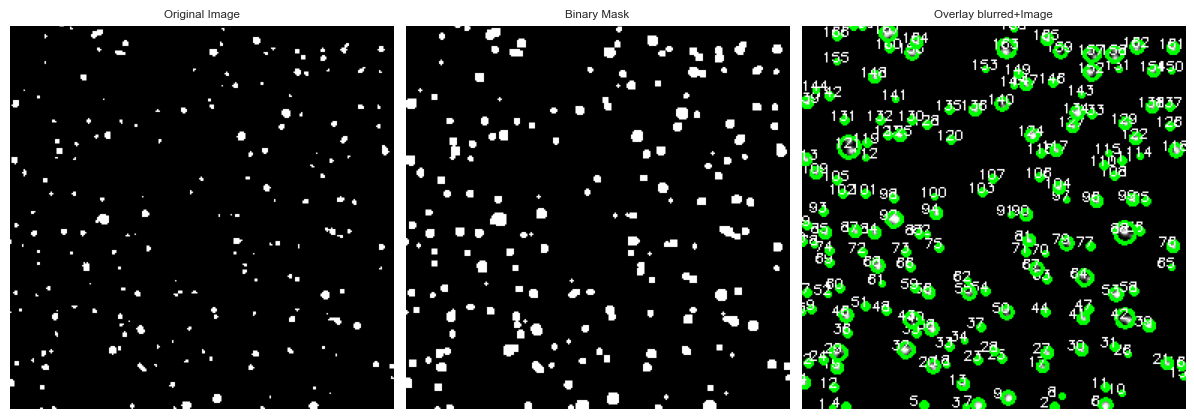

Image shape: (256, 256, 3), dtype: uint8


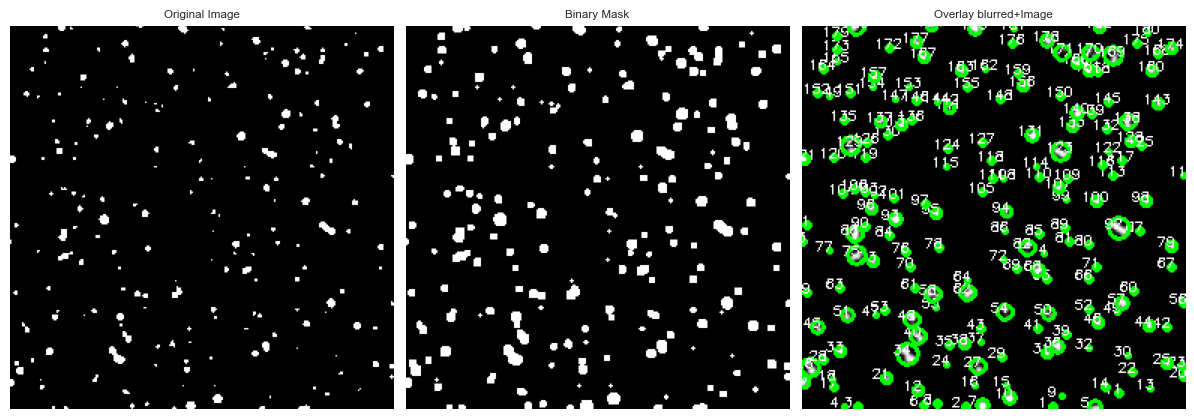

Image shape: (256, 256, 3), dtype: uint8


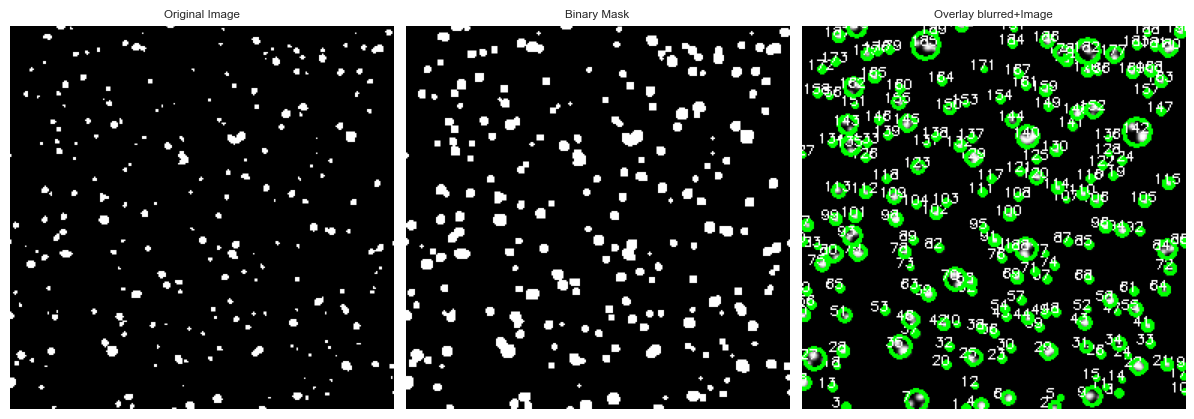

Image shape: (256, 256, 3), dtype: uint8


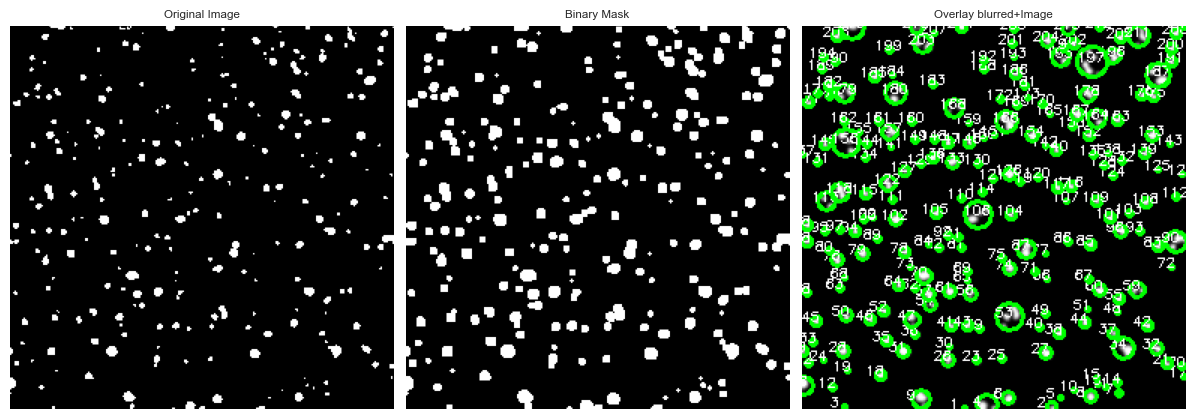

Image shape: (256, 256, 3), dtype: uint8


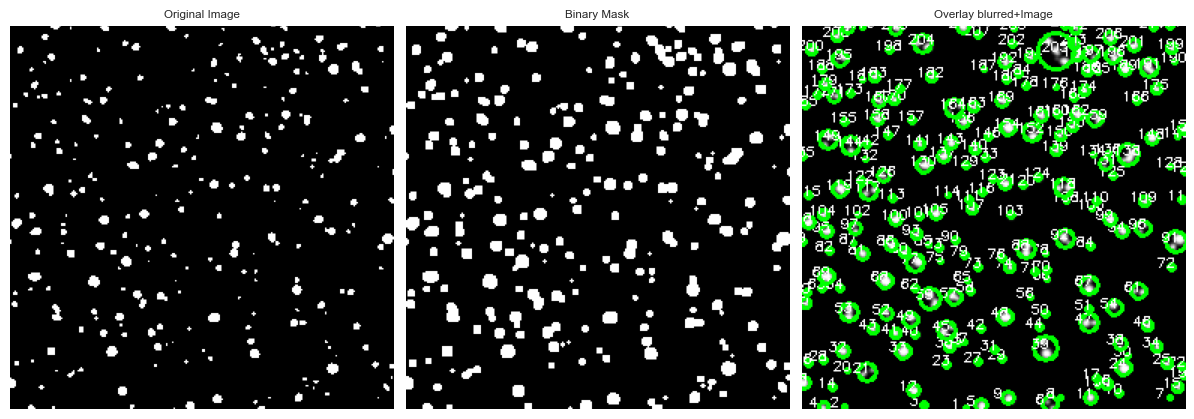

Image shape: (256, 256, 3), dtype: uint8


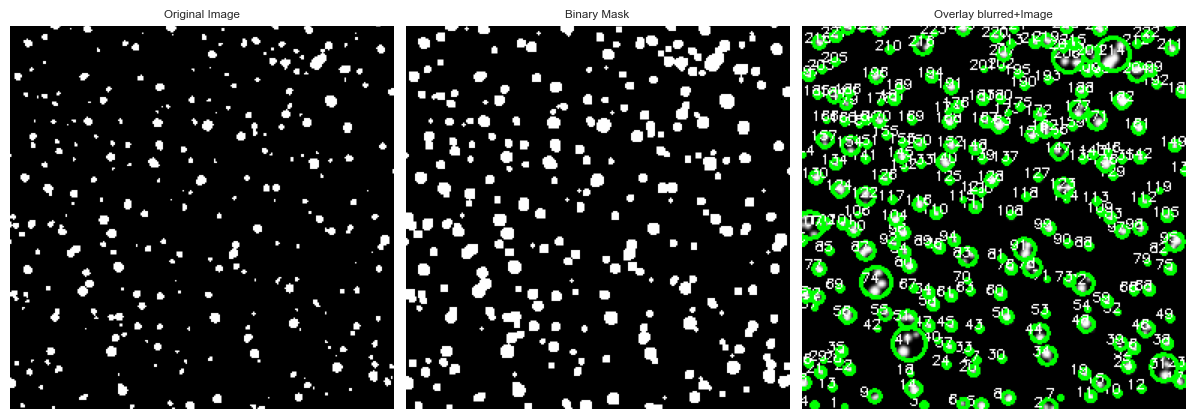

Image shape: (256, 256, 3), dtype: uint8


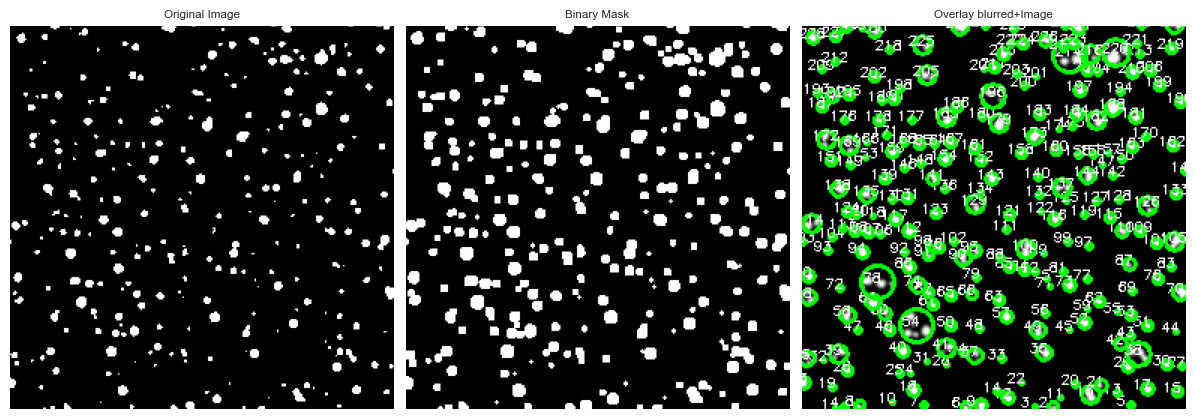

Image shape: (256, 256, 3), dtype: uint8


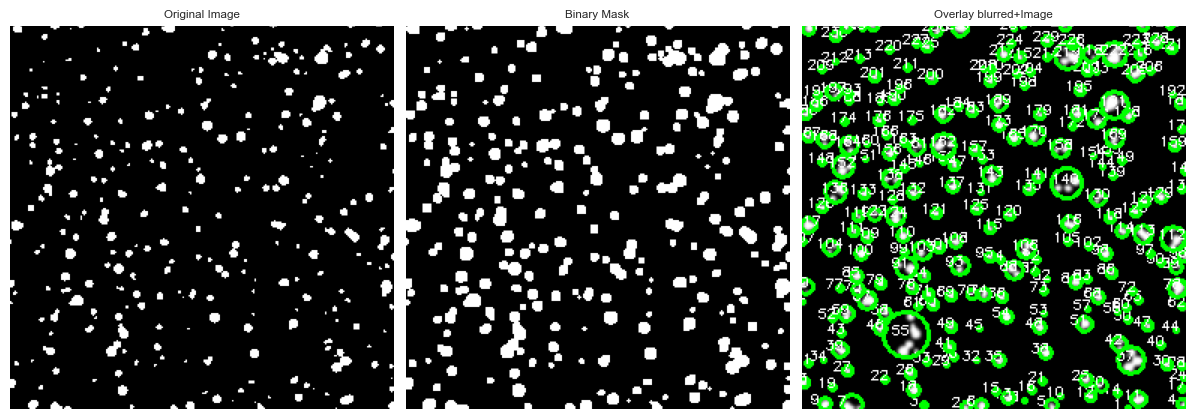

Image shape: (256, 256, 3), dtype: uint8


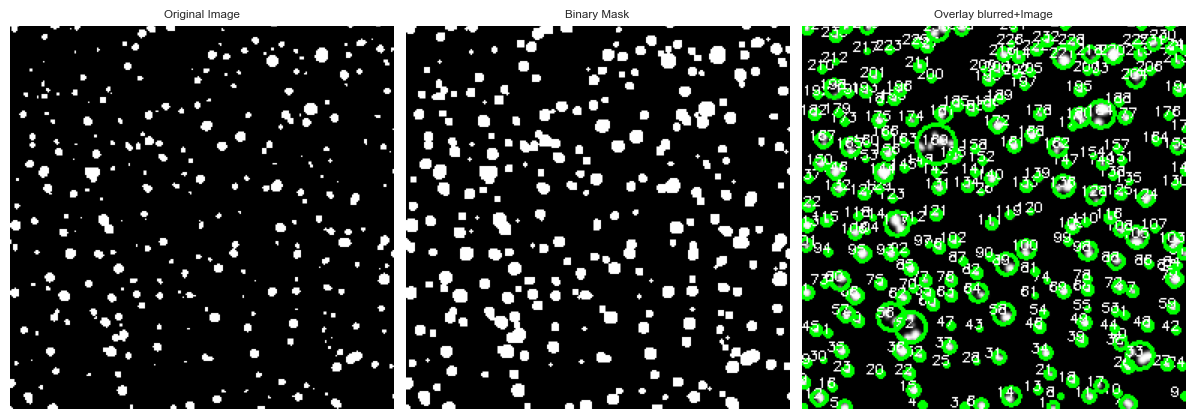

Image shape: (256, 256, 3), dtype: uint8


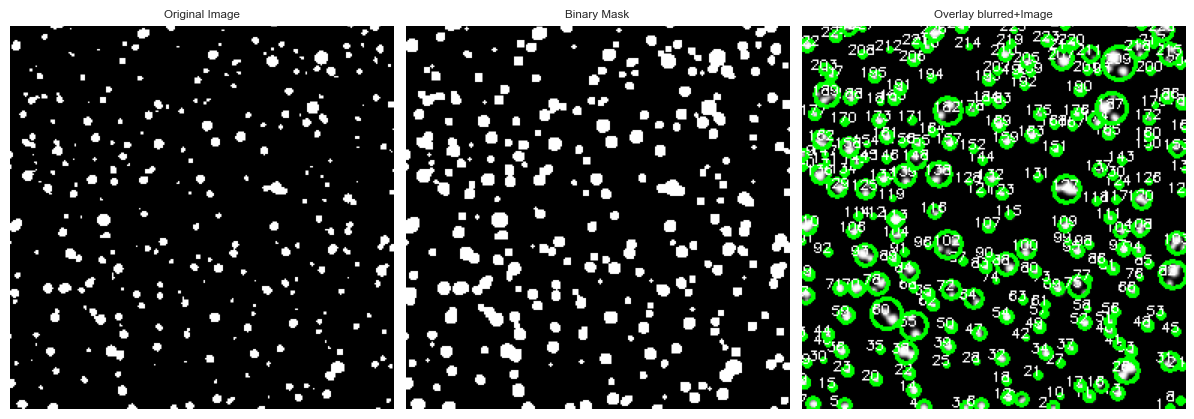

Image shape: (256, 256, 3), dtype: uint8


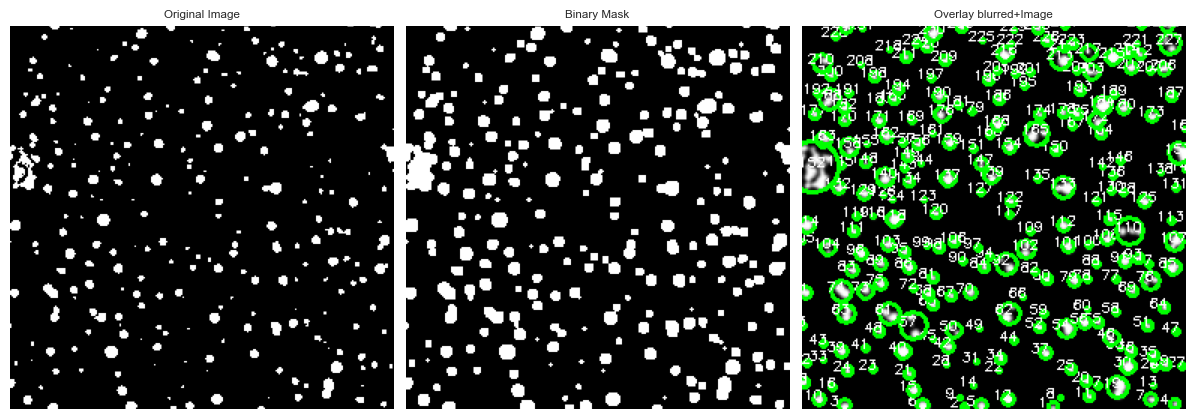

Image shape: (256, 256, 3), dtype: uint8


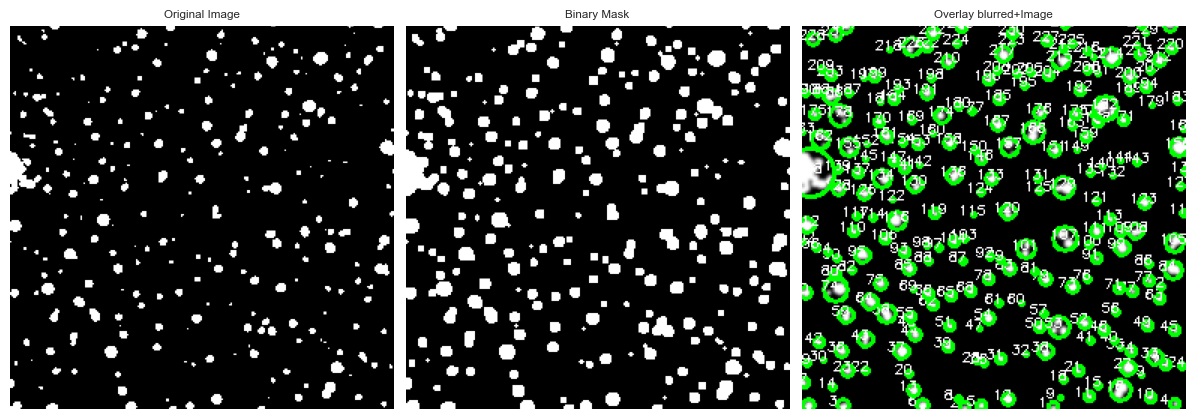

Image shape: (256, 256, 3), dtype: uint8


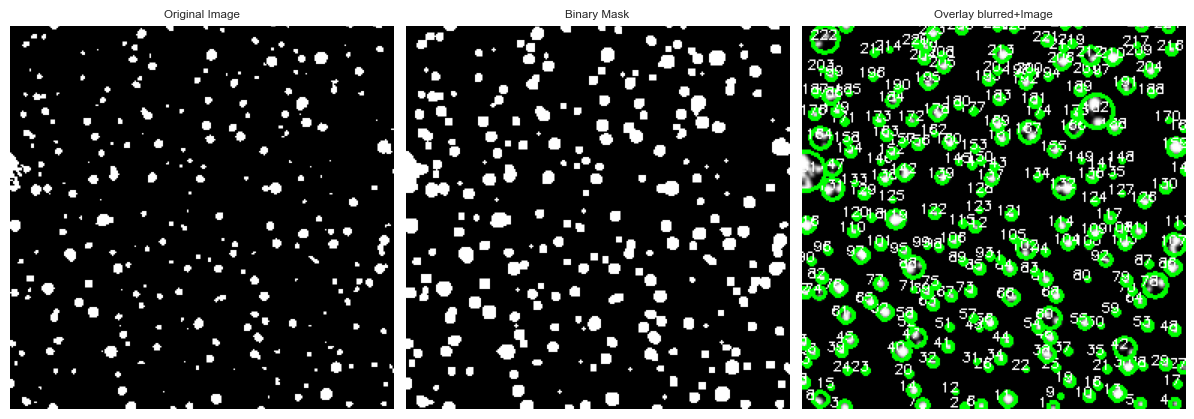

Image shape: (256, 256, 3), dtype: uint8


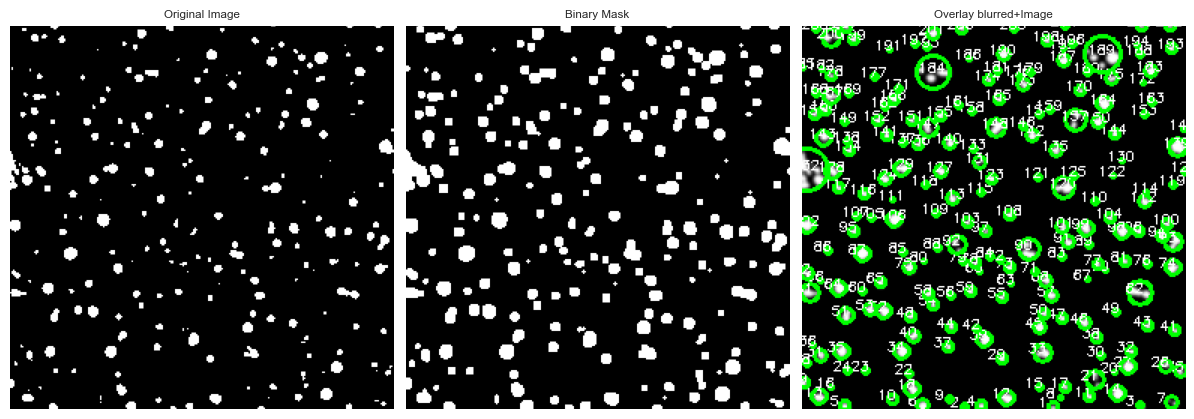

Image shape: (256, 256, 3), dtype: uint8


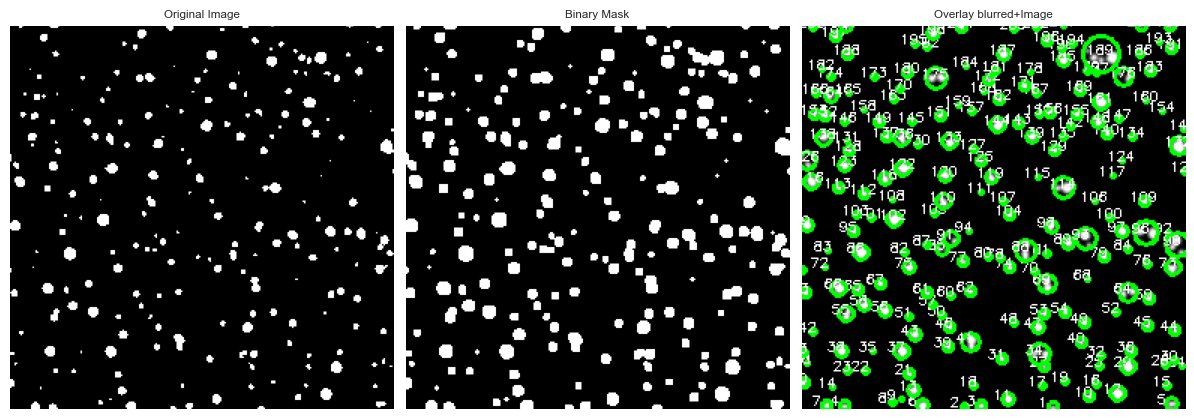

Image shape: (256, 256, 3), dtype: uint8


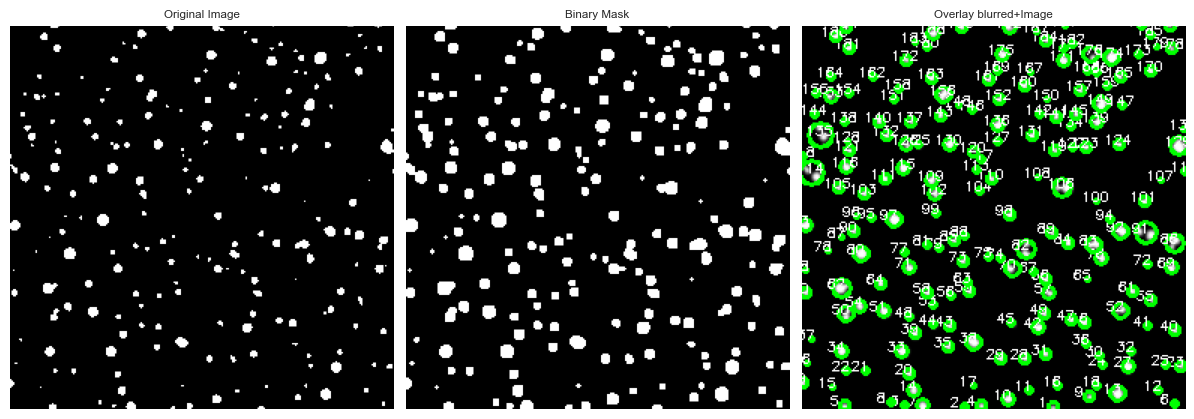

Image shape: (256, 256, 3), dtype: uint8


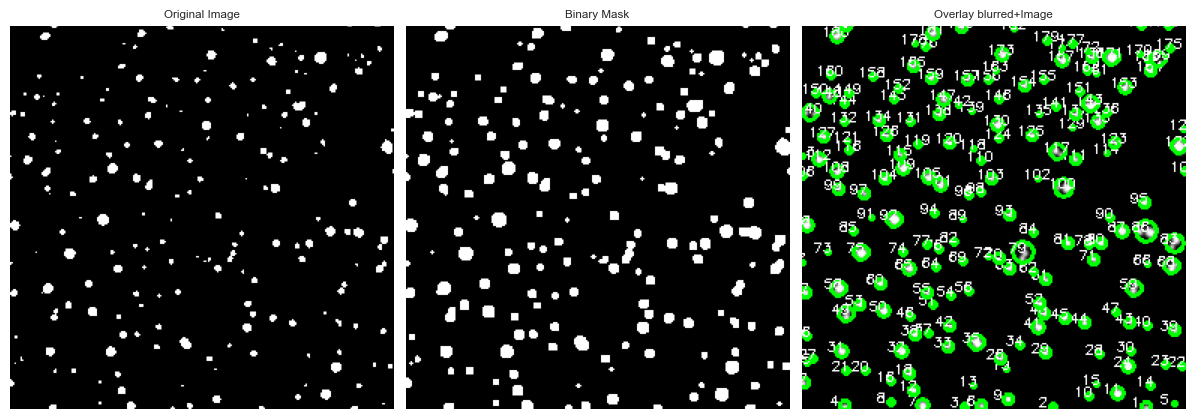

Image shape: (256, 256, 3), dtype: uint8


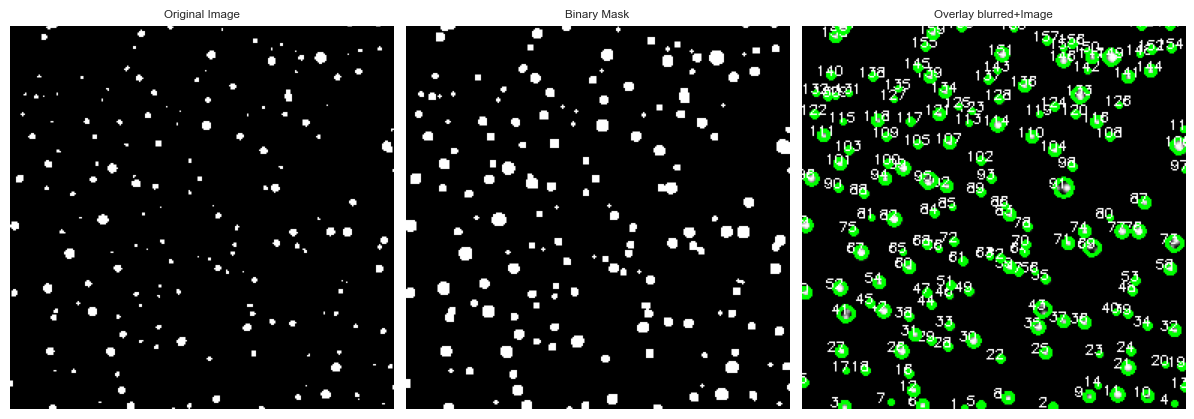

Image shape: (256, 256, 3), dtype: uint8


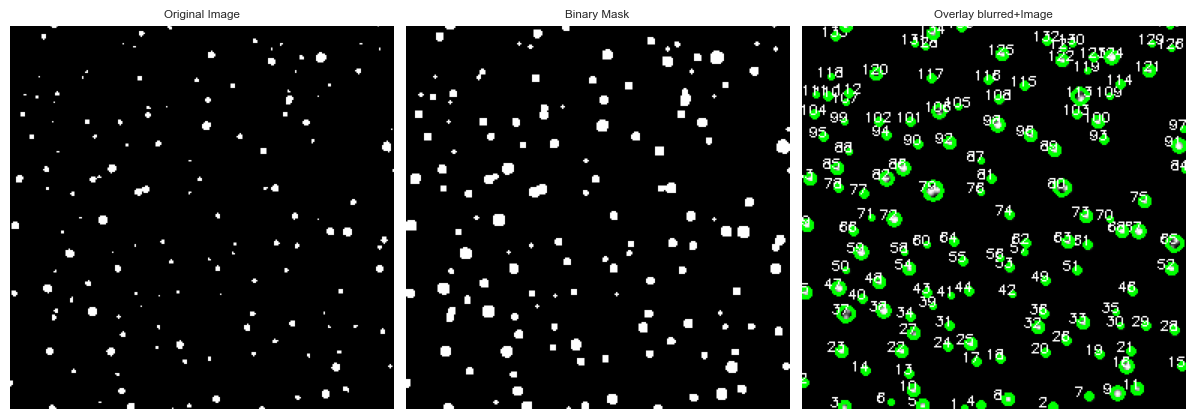

Image shape: (256, 256, 3), dtype: uint8


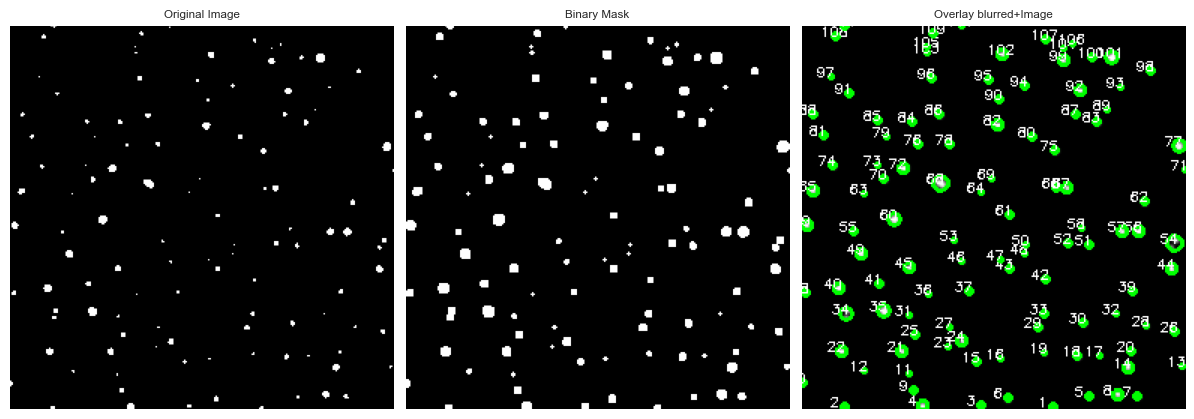

Image shape: (256, 256, 3), dtype: uint8


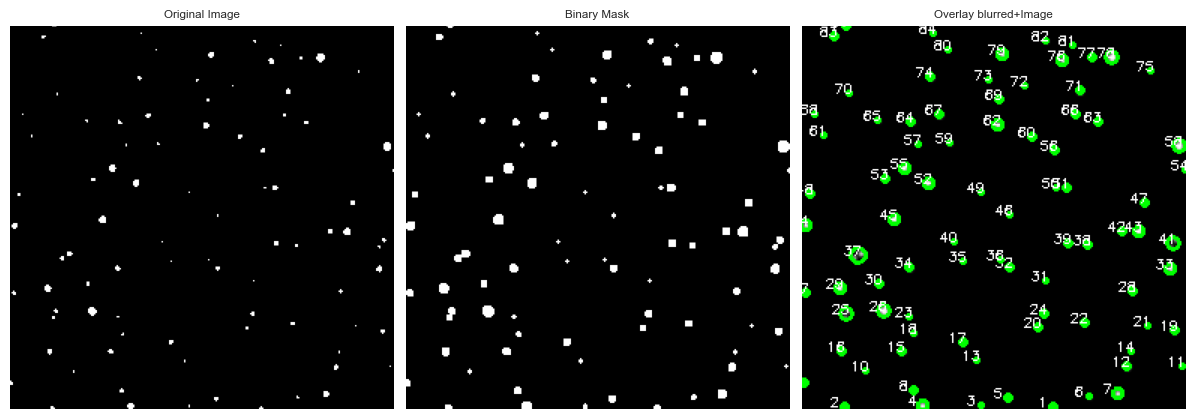

Image shape: (256, 256, 3), dtype: uint8


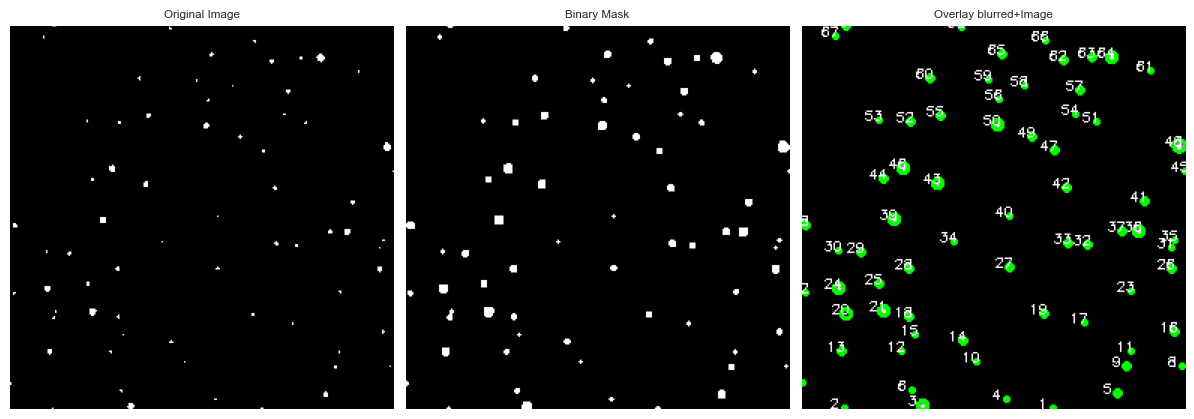

Image shape: (256, 256, 3), dtype: uint8


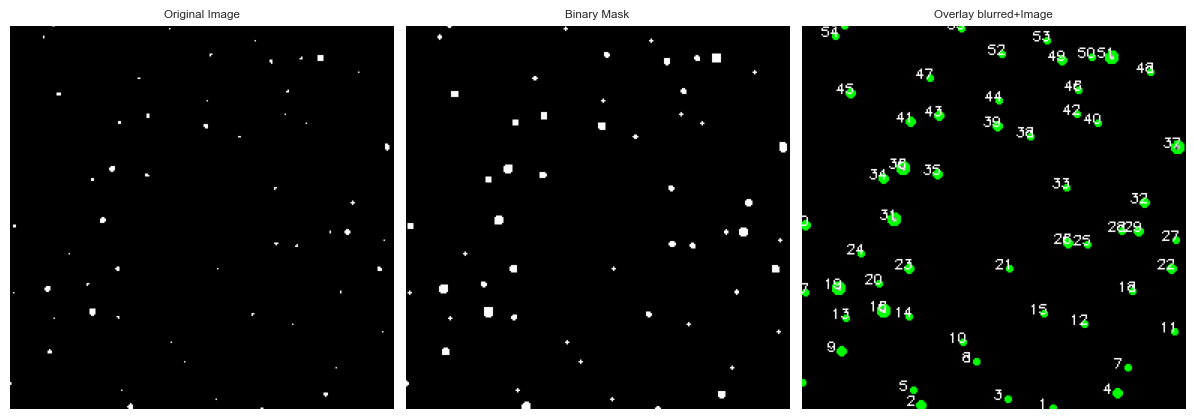

Image shape: (256, 256, 3), dtype: uint8


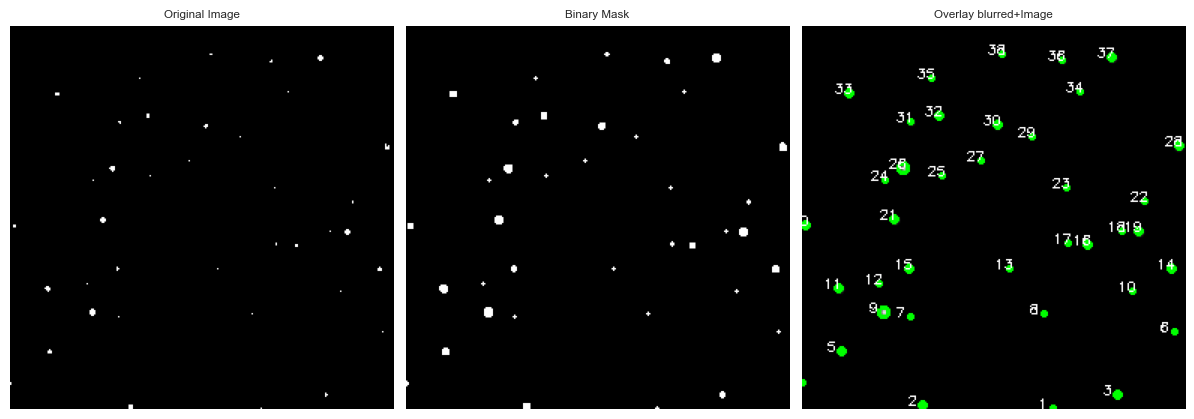

Image shape: (256, 256, 3), dtype: uint8


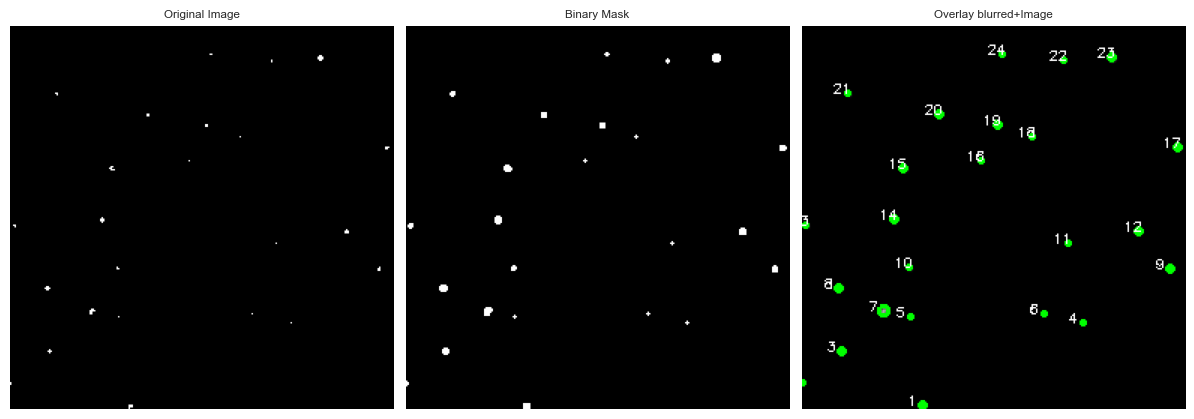

Image shape: (256, 256, 3), dtype: uint8


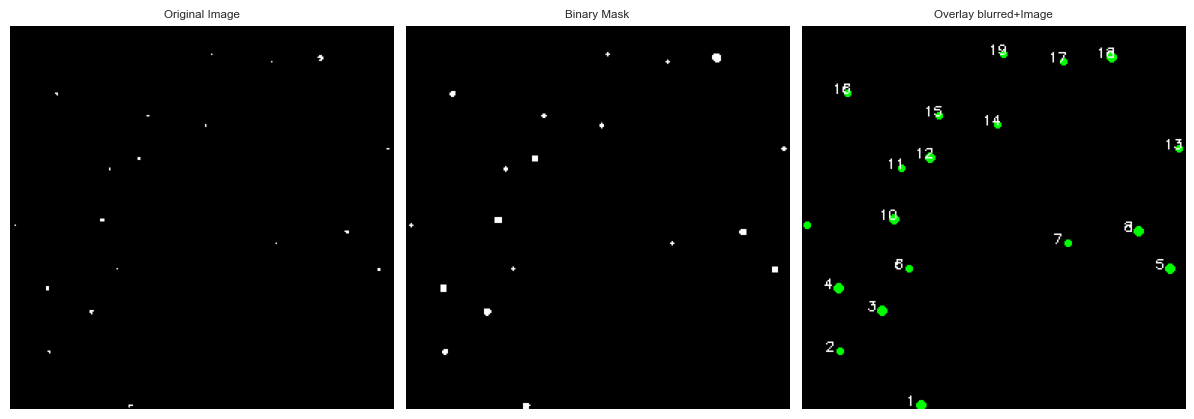

Image shape: (256, 256, 3), dtype: uint8


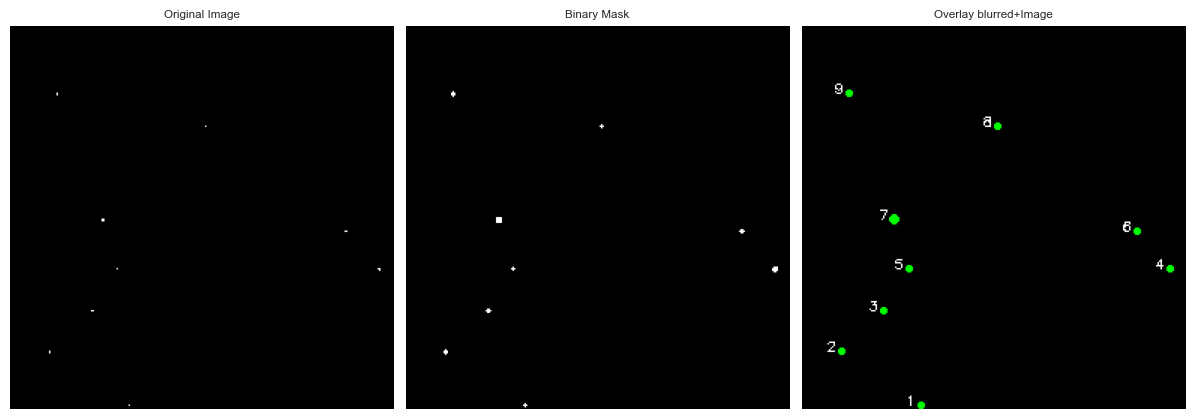

Image shape: (256, 256, 3), dtype: uint8


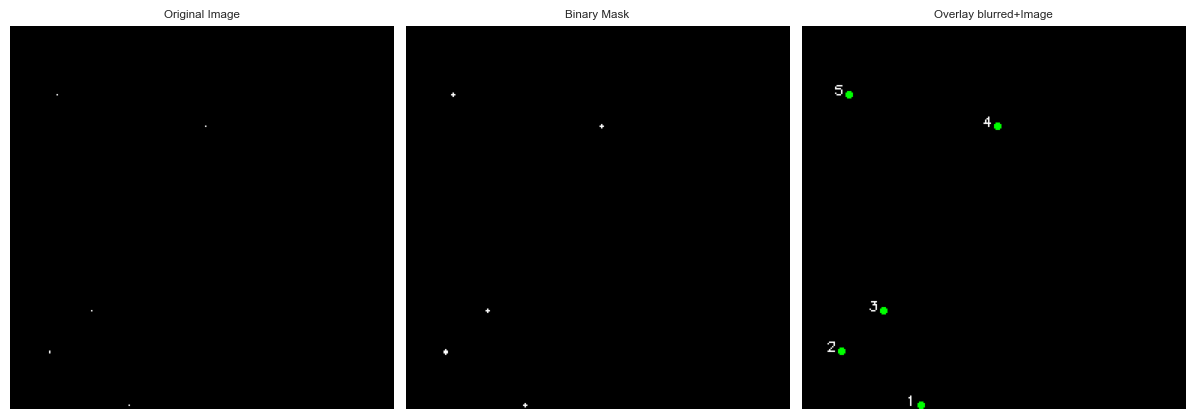

Image shape: (256, 256, 3), dtype: uint8


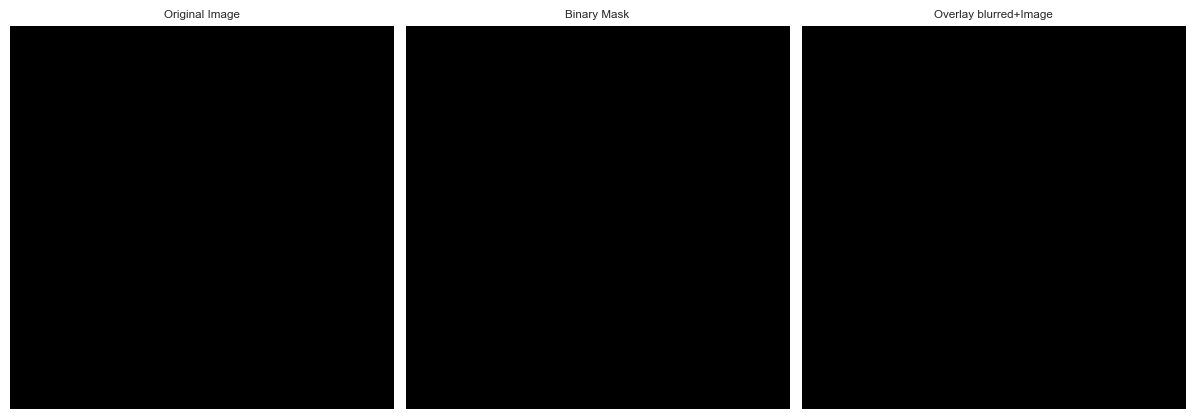

Image shape: (256, 256, 3), dtype: uint8


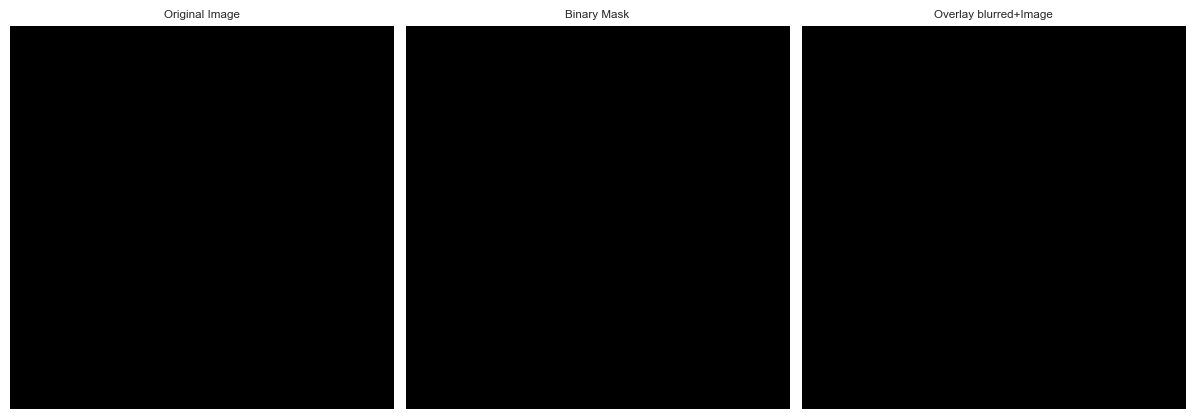

Image shape: (256, 256, 3), dtype: uint8


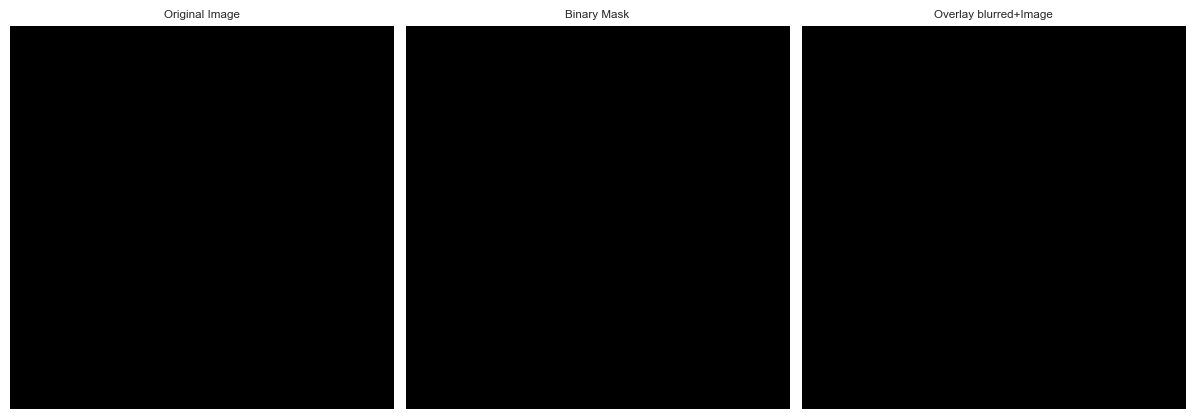

Image shape: (256, 256, 3), dtype: uint8


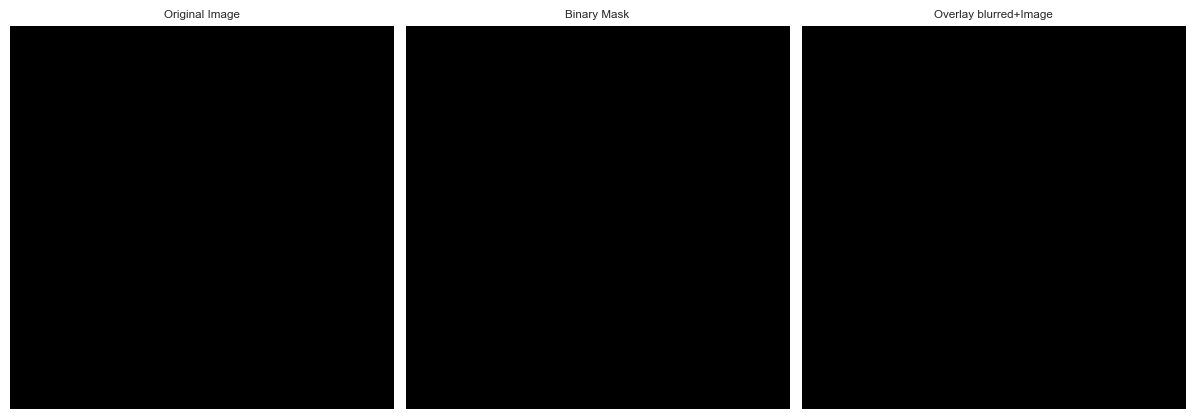

Image shape: (256, 256, 3), dtype: uint8


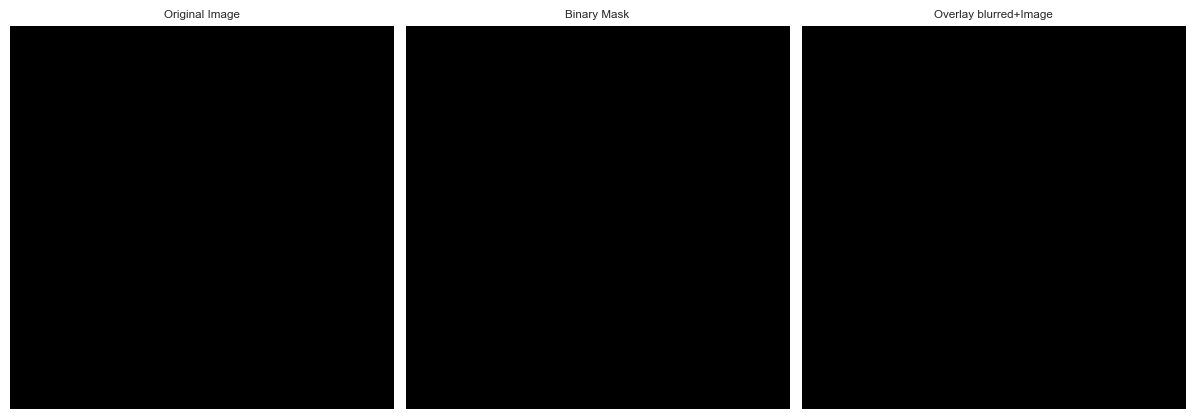

Saved droplet-level CSV: /Users/parth/dev/boekhoven_lab/data/W1_volume//PKU_044-02min09sec_droplet_level.csv
Total droplets: 4381


In [ ]:
##### Following parameters need to be set #####
# Add path of parent folder
directory = "/Users/parth/dev/boekhoven_lab/data/W1_volume/" + "/"
# Add filename of image/stack
filename = "PKU_040_2min03sec.tif"

show_mask_plot = True # True --> shows the threshold and mask of each individual image

##### Further adjustment of the parameters only if really needed #####
# Define the lower boundary
lower_boundary_threshold = 21

##### Code is running with the given parameters #####6
# Extract experiment number from filename
pattern_exp_num = r'PKU_(\d+)_(\d+)min(\d+)sec'
match_exp_num = re.search(pattern_exp_num, filename)
if match_exp_num:
    experiment_num = match_exp_num.group(1)
    start_min = int(match_exp_num.group(2))
    start_sec = int(match_exp_num.group(3))
    # Calculate the Starting time in sec
    starting_t = start_min * 60 + start_sec
    print("Experiment Number:", experiment_num)
    print("Starting Time (sec):", starting_t)
else:
    print("Filename format doesn't match!")

# Generate the path of the video/image for passing on to the counting function
path = directory + '/' + filename

# Create output lists
droplet_num = []
droplet_rad = []
droplet_area = []
drop_mean_circularity = []
drop_deviation_circularity = []

# >>> NEW <<< droplet-level output container
droplet_records = []
droplet_id = 0   #global droplet counter


# Get metadata of the Tif file
with tifffile.TiffFile(path) as tif:
    assert tif.is_imagej
    tags = tif.pages[0].tags
    x_resolution = tags['XResolution'].value
    y_resolution = tags['YResolution'].value

    for page in tif.pages:
        for tag in page.tags:
            tag_name, tag_value = tag.name, tag.value

frame_interval = tif.imagej_metadata['finterval']
pixel_size = 1 / (x_resolution[0] / x_resolution[1])
print(' x-resolution is:', x_resolution,'\n','y-resolution is:',y_resolution,'\n', 'frame rate is:',frame_interval,'\n', 'pixel size:', pixel_size)

# Calculate the minimal droplet size, all droplets below the size won't be counted
minimal_droplet_size_in_pixel = 0.205 / pixel_size #0.242

# Read Tif file with stack or image to count the droplets
_, input = cv2.imreadmulti(path)

for slice_number, image in enumerate(input, start=1):

    imgOriginal = image
    #imgOriginal = cv2.convertScaleAbs(image, 6, 13) # Set lower and upper limit for brightness and contrast adjustments

    # Ensure image is in the correct format
    if len(imgOriginal.shape) == 2:  # Grayscale image
        imgOriginal = cv2.cvtColor(imgOriginal, cv2.COLOR_GRAY2BGR)
    elif len(imgOriginal.shape) == 3 and imgOriginal.shape[2] == 1:  # Single channel
        imgOriginal = cv2.cvtColor(imgOriginal, cv2.COLOR_GRAY2BGR)

    print(f"Image shape: {imgOriginal.shape}, dtype: {imgOriginal.dtype}")

    blurred_img = cv2.GaussianBlur(imgOriginal, (5, 5), 0)
    blurredGray = cv2.cvtColor(blurred_img, cv2.COLOR_BGR2GRAY)

    ret2, thresh = cv2.threshold(
        blurredGray,
        lower_boundary_threshold,
        255,
        cv2.THRESH_BINARY
    )

    # Deep copy for results:
    inputImageCopy = imgOriginal.copy()

    # Find the contours on the binary image:
    contours, hierarchy = cv2.findContours(
        thresh,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )[-2:]

    # Store bounding rectangles and object id here:
    drop_radius = []
    drop_area = []
    drop_circularity = []

    # ObjectCounter:
    objectCounter = 0

    # Look for the outer bounding boxes (no children):
    for _, c in enumerate(contours):

        ((x, y), r) = cv2.minEnclosingCircle(c)

        if r < minimal_droplet_size_in_pixel:
            continue

        objectCounter += 1
        drop_radius.append(r)

        perimeter = cv2.arcLength(c, True)
        area = cv2.contourArea(c)
        if perimeter == 0:
            continue

        circularity = (4 * math.pi * area) / (perimeter * perimeter)
        drop_circularity.append(circularity)

        empty_image = np.zeros_like(inputImageCopy)
        only_one_shape = cv2.drawContours(
            empty_image, [c], -1, (255, 255, 255), thickness=cv2.FILLED
        )
        droplet_area_in_pixel = np.sum(only_one_shape / 255 / 3)
        drop_area.append(droplet_area_in_pixel)

        cv2.circle(blurred_img, (int(x), int(y)), int(r), (0, 255, 0), 2)
        cv2.putText(
            blurred_img, "{}".format(objectCounter),
            (int(x) - 10, int(y)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 255), 1
        )

        # >>> NEW <<< store one droplet = one row
        r_um = pixel_size * r
        area_um2 = droplet_area_in_pixel * pixel_size * pixel_size
        volume_um3 = (4/3) * math.pi * r_um**3
        time_s = starting_t + (slice_number - 1) * frame_interval
        droplet_id += 1
        
        droplet_records.append({
            "Droplet ID": droplet_id,
            "File": filename,
            "Experiment": experiment_num,
            "Slice number": slice_number,
            "Time [s]": time_s,
            "Radius [µm]": r_um,
            "Area [µm^2]": area_um2,
            "Circularity": circularity,
            "Volume [µm^3]": volume_um3
        })

    # calculate the mean circularity of one frame
    if len(drop_circularity) > 1:
        mean_circ = statistics.mean(drop_circularity)
        deviation_circ = statistics.stdev(drop_circularity)
    elif len(drop_circularity) == 1:
        mean_circ = drop_circularity[0]
        deviation_circ = 0
    else:
        mean_circ = 0
        deviation_circ = 0

    # Plot results
    if show_mask_plot:
        fig, axes = plt.subplots(ncols=3, figsize=(12, 6), sharex=True, sharey=True)
        ax = axes.ravel()

        ax[0].imshow(imgOriginal, cmap=plt.cm.nipy_spectral)
        ax[0].set_title('Original Image')
        ax[1].imshow(thresh, cmap=plt.cm.gray)
        ax[1].set_title('Binary Mask')
        ax[2].imshow(blurred_img, cmap=plt.cm.nipy_spectral)
        ax[2].set_title('Overlay blurred+Image')

        for a in ax:
            a.set_axis_off()

        fig.tight_layout()
        plt.show()

    droplet_num.append(objectCounter)
    droplet_rad.append(drop_radius)
    droplet_area.append(drop_area)
    drop_mean_circularity.append(mean_circ)
    drop_deviation_circularity.append(deviation_circ)

# >>> NEW <<< tidy droplet-level CSV output
start_time_str = f"-{start_min:02d}min{start_sec:02d}sec"
output_file = directory + f"PKU_{experiment_num}" + start_time_str + "_droplet_level.csv"
df = pd.DataFrame(droplet_records)
df.to_csv(output_file, index=False)

print("Saved droplet-level CSV:", output_file)
print("Total droplets:", len(df))


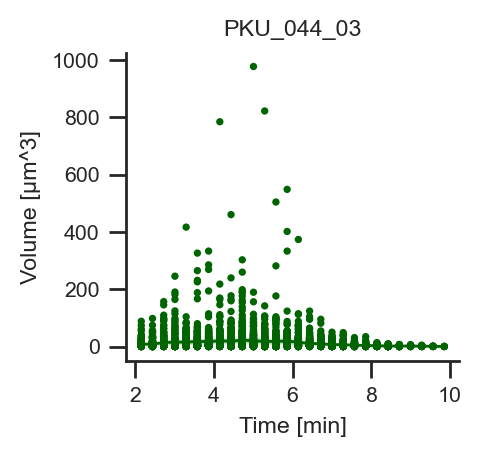

In [ ]:

# Read back the CSV into a pandas DataFrame for plotting
df = pd.read_csv(output_file)
df["Time [min]"] = df["Time [s]"] / 60

fig, ax = plt.subplots(figsize=(2.15, 2), dpi=200)

sns.scatterplot(
    data=df,
    x="Time [min]",
    y='Volume [µm^3]', #'Droplet number',  #or 'mean circularity' or 'deviation circularity' #Volume [µm^3]
    ax=ax,
    edgecolor="none",
    color='darkgreen',
    s=7,
    alpha=1
)

sns.lineplot(
    data=df,
    x="Time [min]",
    y='Volume [µm^3]', #'Droplet number',  #or 'mean circularity' or 'deviation circularity' 
    ax=ax,
    color='darkgreen',
    alpha=1
)

sns.despine(fig, left=False, bottom=False)

ax.set(
    xlabel="Time [min]",
    ylabel="Volume [µm^3]",
    #xticks=(0, 2, 4, 6, 8, 10),
    #xlim=(0, 30),
    title="PKU_040_01"
)


#plot_name = '/' + specified_name + '_droplet_count_plot.png'
#plt.savefig(directory + plot_name, dpi=2000, bbox_inches="tight", transparent=True)
plt.show()




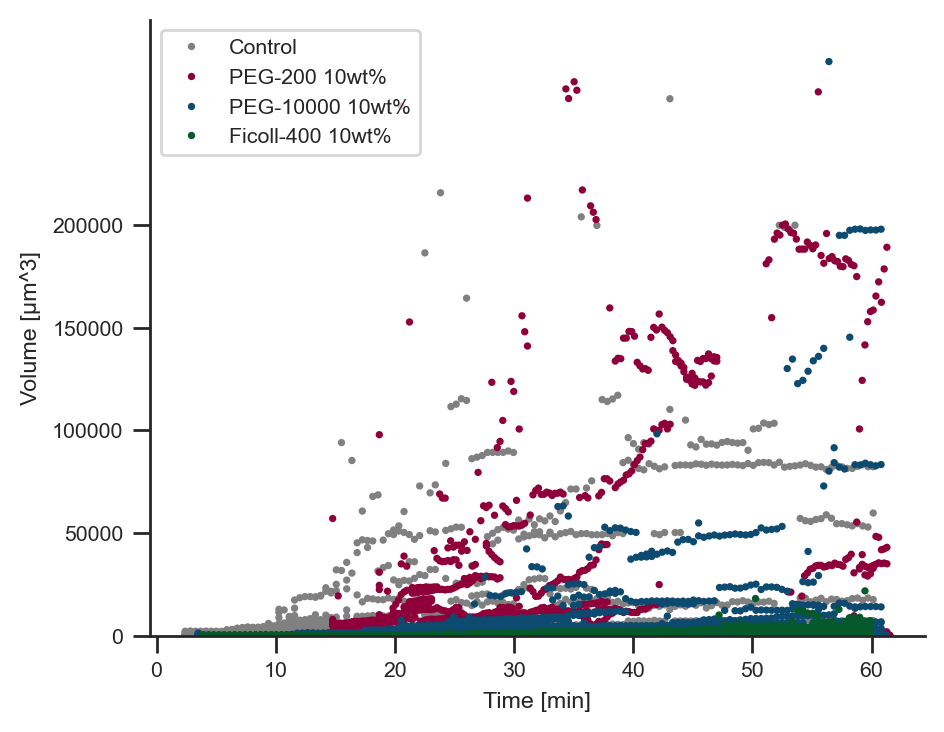

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---- Load all datasets ----
files = [
    "/Users/parth/dev/boekhoven_lab/data/CG2_no_edc//PKU_011-02min24sec_droplet_level.csv",
    "/Users/parth/dev/boekhoven_lab/data/CG2_no_edc//PKU_012-14min47sec_droplet_level.csv",
    "/Users/parth/dev/boekhoven_lab/data/CG2_no_edc//PKU_013-03min30sec_droplet_level.csv",
    "/Users/parth/dev/boekhoven_lab/data/CG2_no_edc//PKU_014-03min54sec_droplet_level.csv"
]

dfs = []

for i, f in enumerate(files):
    df = pd.read_csv(f)
    df["Time [min]"] = df["Time [s]"] / 60
    df["dataset"] = f"Dataset {i+1}"
    dfs.append(df)

# ---- Combine ----
df = pd.concat(dfs, ignore_index=True)

df["dataset"] = df["dataset"].replace({
    "Dataset 1": "Control",
    "Dataset 2": "PEG-200 10wt%",
    "Dataset 3": "PEG-10000 10wt%",
    "Dataset 4": "Ficoll-400 10wt%"
})

palette = {
    "Control": "#808080",
    "PEG-200 10wt%": "#8F003B",
    "PEG-10000 10wt%": "#0D4A70",
    "Ficoll-400 10wt%": "#06592A"
}

# ---- Plot ----
fig, ax = plt.subplots(figsize=(5, 4), dpi=200)

sns.scatterplot(
    data=df,
    x="Time [min]",
    y="Volume [µm^3]",
    hue="dataset",  
    palette=palette,      
    ax=ax,
    edgecolor="none",
    s=7,
    alpha=1
)

'''
sns.lineplot(
    data=df,
    x="Time [min]",
    y="Volume [µm^3]",
    hue="dataset", 
    palette=palette,       
    ax=ax,
    alpha=1,
    legend=False         
)
'''

sns.despine(fig, left=False, bottom=False)

ax.set(
    xlabel="Time [min]",
    ylabel="Volume [µm^3]",
    yticks=(0, 50000, 100000, 150000, 200000, 250000, 300000),
    ylim=(0, 300000),
)

ax.legend(title="")

plt.show()